# Brick 4: Narrative Communities

**Improvements over v1**
1. Config dataclass — all tuneable constants in one place.
2. Graceful degradation — every figure degrades cleanly when optional data files are missing.
3. Defensive column resolution — detects alternative column names for labels, years, votes, etc.
4. Richer lollipop (Fig 2) — gradient bar fill, size share annotation.
5. Improved major/minor split (Fig 3) — diverging waffle-style proportion bar.
6. Better index table (Fig 4) — alternating row shading, color-coded left accent strip.
7. Community profile sheets (Fig 5) — vote-average sparkline card and example strip.
8. Representative gallery (Fig 6) — sorted by size, color-coded header band.
9. Bubble chart (Fig 7) — log-scaled sizes, improved annotation placement.
10. Genre small-multiples (Fig 8) — sorted bars, value labels.
11. Interpretation summary (Fig 9) — cleaner card grid with icon glyphs.
12. Full output check with byte sizes.
13. All helpers documented and typed.

In [6]:
!pip install adjustText

In [1]:
# ---------------------------------------------------------------------------
# 0. Google Colab Setup (Mount Drive)
# ---------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

print("\nGoogle Drive mounted successfully! You can now access your thesis folders.")

Mounted at /content/drive

Google Drive mounted successfully! You can now access your thesis folders.


In [2]:
# ---------------------------------------------------------------------------
# 1. Imports & global config
# ---------------------------------------------------------------------------
import os
import re
import math
import textwrap
import warnings
from dataclasses import dataclass, field
from pathlib import Path
from collections import defaultdict
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import matplotlib.patheffects as pe
import matplotlib.ticker as ticker

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)
pd.set_option("display.max_colwidth", 240)

# ---------------------------------------------------------------------------
# Colour palette & Matplotlib Config
# ---------------------------------------------------------------------------
COL = {
    "ink":          "#1A1A2E",
    "muted":        "#5A6072",
    "grid":         "#E4E7EB",
    "panel":        "#F7F8FA",
    "blue":         "#2F6FB3",
    "orange":       "#D06C45",
    "green":        "#2F8F5B",
    "purple":       "#7A5BC2",
    "red":          "#C94C4C",
    "yellow":       "#D9A21B",
    "teal":         "#26A69A",
    "light_blue":   "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green":  "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_yellow": "#FDF6E3",
    "light_teal":   "#E0F4F2",
    "light_gray":   "#F2F4F7",
    "white":        "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7", "#F28E2B", "#59A14F", "#E15759", "#76B7B2", "#9C755F",
    "#EDC948", "#B07AA1", "#FF9DA7", "#BAB0AC", "#2F6FB3", "#D06C45",
    "#2F8F5B", "#7A5BC2", "#C94C4C", "#D9A21B", "#5C6BC0", "#26A69A",
    "#AB47BC", "#8D6E63", "#78909C", "#EC407A", "#43A047", "#FB8C00",
    "#6D4C41", "#00ACC1",
]

plt.rcParams.update({
    "figure.facecolor":    "white",
    "axes.facecolor":      "white",
    "axes.edgecolor":      COL["ink"],
    "axes.labelcolor":     COL["ink"],
    "xtick.color":         COL["ink"],
    "ytick.color":         COL["ink"],
    "text.color":          COL["ink"],
    "font.family":         "DejaVu Sans",
    "font.size":           12,
    "axes.titlesize":      17,
    "axes.titleweight":    "bold",
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "savefig.dpi":         320,
    "figure.dpi":          130,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
})

# ---------------------------------------------------------------------------
# Config & Paths (Mapping to Google Drive)
# ---------------------------------------------------------------------------
@dataclass
class Config:
    project_dir:       Path  = Path("/content/drive/MyDrive/thesis_movie_project") # <-- Ensure this matches your Drive folder
    major_threshold:   int   = 100    # min films for a community to be "major"
    lollipop_top_n:    int   = 18     # communities shown in lollipop chart
    gallery_top_n:     int   = 12     # communities in representative gallery
    genre_top_n:       int   = 8      # communities in genre small-multiples
    profile_top_n:     int   = 8      # individual profile sheets to generate
    index_top_n:       int   = 12     # rows in the index table
    bubble_top_n:      int   = 23     # communities in bubble chart
    max_examples:      int   = 5      # max example films per community
    fig_dpi:           int   = 320
    wrap_label:        int   = 36     # char width for y-tick labels
    wrap_example:      int   = 42
    wrap_interp:       int   = 42
    summary_total_communities: int = 26   # shown in summary card

CFG = Config()

# Derived paths
FINAL_DIR  = CFG.project_dir / "outputs" / "thesis_bricks" / "04_narrative_communities"
FIG_DIR    = FINAL_DIR / "figures"
TABLE_DIR  = FINAL_DIR / "tables"
TEXT_DIR   = FINAL_DIR / "text"
PROC_NET   = CFG.project_dir / "processed" / "network"
PROC_CORE  = CFG.project_dir / "processed" / "core"
OUT_TABLES = CFG.project_dir / "outputs" / "tables"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

## Helper Utilities

In [3]:
def community_color(cid) -> str:
    try:
        return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception:
        return COL["blue"]

def safe_read(path) -> Optional[pd.DataFrame]:
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print(f"  [SKIP] Missing: {path}")
    return None

def save_fig(fig: plt.Figure, name: str, dpi: int = None) -> None:
    dpi = dpi or CFG.fig_dpi
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print(f"  Saved: {png}")

def save_table(df: pd.DataFrame, name: str) -> Path:
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print(f"  Saved: {path}")
    return path

def write_text(txt: str, name: str) -> Path:
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print(f"  Saved: {path}")
    return path

def wrap_text(s, width: int = 42) -> str:
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width: int = 90) -> str:
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="…")

def clean_title(x) -> str:
    if pd.isna(x):
        return ""
    return str(x).replace("\n", " ").strip()

def fmt_int(x) -> str:
    try:
        return f"{int(round(float(x))):,}"
    except Exception:
        return "—"

def resolve_col(df: pd.DataFrame, candidates: list[str], fallback: str = "") -> str:
    for c in candidates:
        if c in df.columns:
            return c
    return fallback

def parse_examples(s, max_n: int = 4) -> list[str]:
    if pd.isna(s):
        return []
    parts = re.split(r";|,|\|", str(s))
    out = []
    for p in parts:
        p = p.strip()
        if p and p.lower() not in ("nan", "none", ""):
            out.append(p)
        if len(out) >= max_n:
            break
    return out

def first_available(row: pd.Series, cols: list[str]) -> str:
    for c in cols:
        if c in row.index and pd.notna(row[c]) and str(row[c]).strip():
            return str(row[c])
    return ""

def parse_genre_mix(x, max_n: int = 5) -> list[tuple[str, float]]:
    if pd.isna(x):
        return []
    pairs = []
    for ch in re.split(r",|;", str(x)):
        ch = ch.strip()
        if not ch:
            continue
        genre = re.sub(r"[:(].*", "", ch).strip()
        m = re.search(r"([0-9]+\.?[0-9]*)", ch)
        value = float(m.group(1)) if m else np.nan
        if genre:
            pairs.append((genre, value))
        if len(pairs) >= max_n:
            break
    return pairs

def title_block(fig: plt.Figure, title: str, subtitle: str = None, x: float = 0.05, y: float = 0.965) -> None:
    fig.text(x, y, title, ha="left", va="top", fontsize=21, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.052, subtitle, ha="left", va="top", fontsize=12, color=COL["muted"])

def add_card(ax, x0, y0, w, h, value, label, bg_color, *, transform=None):
    t = transform or ax.transAxes
    ax.add_patch(FancyBboxPatch(
        (x0, y0), w, h,
        boxstyle="round,pad=0.018,rounding_size=0.02",
        facecolor=bg_color, edgecolor="none",
        transform=t, zorder=2,
    ))
    mid_x = x0 + w / 2
    ax.text(mid_x, y0 + h * 0.62, value, transform=t, ha="center", va="center", fontsize=22, fontweight="bold", zorder=3)
    ax.text(mid_x, y0 + h * 0.22, label, transform=t, ha="center", va="center", fontsize=10.5, color=COL["muted"], zorder=3)

def nudge_annotations(ax, texts, x_arr, y_arr):
    positions = list(zip(x_arr, y_arr))
    used = []
    for i, (xi, yi) in enumerate(positions):
        yi_new = yi
        for (xj, yj) in used:
            if abs(xi - xj) < 3 and abs(yi_new - yj) < 30:
                yi_new += 35
        used.append((xi, yi_new))
        texts[i].set_position((xi + 0.5, yi_new + 25))

## 1. Load Data

In [4]:
print("=" * 60)
print("Loading files …")
print("=" * 60)

FILES = {
    "nodes":                  PROC_NET   / "semantic_network_nodes_lcc.csv",
    "edges":                  PROC_NET   / "semantic_network_edges_mutual_knn.csv",
    "community_labels":       OUT_TABLES / "community_manual_labeling_template_labeled.csv",
    "community_size":         OUT_TABLES / "community_size_overview.csv",
    "major_community_table":  OUT_TABLES / "major_community_thesis_table.csv",
    "community_reps":         OUT_TABLES / "community_representative_films_long.csv",
    "top_visible_central":    OUT_TABLES / "top_visible_central_films_per_community.csv",
    "community_success":      OUT_TABLES / "final_story_tables" / "final_community_success_summary.csv",
}

for k, p in FILES.items():
    status = "✓" if p.exists() else "✗ MISSING"
    print(f"  {status}  {k}")

nodes               = safe_read(FILES["nodes"])
community_labels    = safe_read(FILES["community_labels"])
community_reps      = safe_read(FILES["community_reps"])
top_visible_central = safe_read(FILES["top_visible_central"])
community_success   = safe_read(FILES["community_success"])

if nodes is None or community_labels is None:
    print("[WARNING] Essential files missing for rendering.\n Please ensure 'semantic_network_nodes_lcc.csv' and 'community_manual_labeling_template_labeled.csv' exist in your Drive.")
else:
    LABEL_COL = resolve_col(community_labels, ["suggested_label_manual", "narrative_label", "label"], "narrative_label")
    NOTE_COL  = resolve_col(community_labels, ["interpretation_note_manual", "interpretation", "note"], "interpretation")
    YEAR_COL  = resolve_col(nodes, ["release_year", "year", "film_year"], "")
    VOTE_AVG  = resolve_col(nodes, ["vote_average", "rating", "avg_rating"], "")
    VOTE_CNT  = resolve_col(nodes, ["vote_count", "n_votes", "vote_n"], "")

    print(f"\n  label col : {LABEL_COL}")
    print(f"  note col  : {NOTE_COL}")
    print(f"  year col  : {YEAR_COL or '(none)'}")
    print(f"  vote avg  : {VOTE_AVG or '(none)'}")

Loading files …
  ✓  nodes
  ✓  edges
  ✓  community_labels
  ✓  community_size
  ✓  major_community_table
  ✓  community_reps
  ✓  top_visible_central
  ✓  community_success

  label col : suggested_label_manual
  note col  : interpretation_note_manual
  year col  : release_year
  vote avg  : vote_average


## 2. Build Profile Table

In [5]:
if nodes is not None and community_labels is not None:
    print("\n" + "=" * 60)
    print("Building community profile …")
    print("=" * 60)

    comm = community_labels.copy()
    comm["community_id"] = pd.to_numeric(comm["community_id"], errors="coerce").astype("Int64")

    if "n_films" not in comm.columns:
        sizes = nodes.groupby("community_id").size().reset_index(name="n_films")
        comm = comm.merge(sizes, on="community_id", how="left")

    comm = comm.sort_values("n_films", ascending=False).reset_index(drop=True)

    total_nodes       = len(nodes)
    total_communities = int(nodes["community_id"].nunique())
    major_count       = int((comm["n_films"] >= CFG.major_threshold).sum())
    minor_count       = total_communities - major_count

    if "share_of_network_pct" not in comm.columns:
        comm["share_of_network_pct"] = comm["n_films"] / total_nodes * 100

    agg_spec = {"n_nodes": ("community_id", "size")}
    if YEAR_COL:
        agg_spec.update({
            "median_year": (YEAR_COL, "median"),
            "min_year":    (YEAR_COL, "min"),
            "max_year":    (YEAR_COL, "max"),
        })
    if VOTE_AVG:
        agg_spec["median_vote_average"] = (VOTE_AVG, "median")
    if VOTE_CNT:
        agg_spec["median_vote_count"] = (VOTE_CNT, "median")

    node_stats = nodes.groupby("community_id").agg(**agg_spec).reset_index()
    profile = comm.merge(node_stats, on="community_id", how="left", suffixes=("", "_node"))

    if community_success is not None:
        extra = [c for c in community_success.columns if c not in profile.columns or c == "community_id"]
        profile = profile.merge(community_success[extra], on="community_id", how="left", suffixes=("", "_success"))

    example_lookup: dict[int, list[str]] = {}
    _src = top_visible_central if top_visible_central is not None else community_reps
    if _src is not None:
        title_c = resolve_col(_src, ["title", "film_title", "movie_title"], "")
        year_c  = resolve_col(_src, ["release_year", "year"], "")
        for cid, g in _src.groupby("community_id"):
            titles = []
            for _, row in g.head(CFG.max_examples).iterrows():
                if title_c:
                    t = clean_title(row[title_c])
                    yr = f" ({int(row[year_c])})" if year_c and pd.notna(row.get(year_c)) else ""
                    titles.append(t + yr)
            example_lookup[int(cid)] = titles

    def get_examples(row: pd.Series) -> str:
        cid = int(row["community_id"])
        if cid in example_lookup and example_lookup[cid]:
            return "; ".join(example_lookup[cid])
        fallback = first_available(row, ["visible_titles_vote_count", "central_titles_weighted_degree", "recognizable_examples", "selected_examples"])
        return "; ".join(parse_examples(fallback, max_n=CFG.max_examples))

    profile["selected_examples"] = profile.apply(get_examples, axis=1)
    save_table(profile, "00_community_profile_table.csv")

    print(f"  nodes              : {total_nodes:,}")
    print(f"  communities        : {total_communities}")
    print(f"  major (≥{CFG.major_threshold})     : {major_count}")
    print(f"  minor              : {minor_count}")


Building community profile …
  Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/tables/00_community_profile_table.csv
  nodes              : 19,202
  communities        : 26
  major (≥100)     : 23
  minor              : 3


## Visualizations (Figures 1 - 9)

In [12]:
if nodes is not None:
    print("\n[Fig 1] Community detection concept …")
    fig, ax = plt.subplots(figsize=(14, 7.5))
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    title_block(fig, "What community detection means in the plot-similarity network", "Communities are groups of films with denser story-similarity links inside the group than outside it.")

    _left  = {"A1": (0.15, 0.60), "A2": (0.25, 0.70), "A3": (0.28, 0.50), "A4": (0.16, 0.42)}
    _right = {"B1": (0.70, 0.62), "B2": (0.80, 0.72), "B3": (0.83, 0.50), "B4": (0.71, 0.40)}
    _mid   = {"M": (0.48, 0.54)}

    def _draw_group(grp, color, label_text, lx, ly):
        keys = list(grp.keys())
        for i in range(len(keys)):
            for j in range(i + 1, len(keys)):
                x1, y1 = grp[keys[i]]
                x2, y2 = grp[keys[j]]
                ax.plot([x1, x2], [y1, y2], color=color, lw=2.5, alpha=0.30, zorder=1)
        for k, (x, y) in grp.items():
            ax.scatter(x, y, s=1300, color="white", edgecolor=color, linewidth=2.5, zorder=3)
            ax.text(x, y, k, ha="center", va="center", fontsize=11, fontweight="bold", color=color, zorder=4)
        from matplotlib.patches import Ellipse
        ex = np.mean([v[0] for v in grp.values()])
        ey = np.mean([v[1] for v in grp.values()])
        el = Ellipse((ex, ey), width=0.22, height=0.36, facecolor=color, alpha=0.07, edgecolor=color, linewidth=1.5, linestyle="--", zorder=0)
        ax.add_patch(el)
        ax.text(lx, ly, label_text, ha="center", fontsize=12, fontweight="bold", color=color)

    _draw_group(_left,  COL["blue"],   "Community 1\nstory neighborhood A", 0.20, 0.26)
    _draw_group(_right, COL["orange"], "Community 2\nstory neighborhood B", 0.77, 0.26)

    x_mid, y_mid = _mid["M"]
    for key, grp in [("A2", _left), ("A3", _left), ("B1", _right), ("B4", _right)]:
        x1, y1 = grp[key]
        ax.plot([x1, x_mid], [y1, y_mid], color=COL["grid"], lw=1.8, alpha=0.8, zorder=1)
    ax.scatter(x_mid, y_mid, s=1400, color="white", edgecolor=COL["purple"], linewidth=2.5, zorder=3)
    ax.text(x_mid, y_mid, "M", ha="center", va="center", fontsize=11, fontweight="bold", color=COL["purple"], zorder=4)
    ax.text(x_mid, 0.30, "bridge film —\nfewer inter-community links", ha="center", fontsize=10.5, color=COL["muted"])
    ax.text(0.5, 0.12, "In this thesis, a community is interpreted as a narrative neighborhood, not as a fixed genre.", ha="center", fontsize=12.5, color=COL["muted"], style="italic")
    ax.axhline(0.10, xmin=0.08, xmax=0.92, color=COL["grid"], lw=1)
    save_fig(fig, "01_community_detection_concept.png")
    plt.show()

    # --- Fig 2 ---
    print("\n[Fig 2] Major communities lollipop …")
    plot2 = profile.sort_values("n_films", ascending=True).tail(CFG.lollipop_top_n).copy()
    fig, ax = plt.subplots(figsize=(13, 9))
    y = np.arange(len(plot2))
    max_val = plot2["n_films"].max()
    for yi, (_, row) in zip(y, plot2.iterrows()):
        cid   = int(row["community_id"])
        n     = int(row["n_films"])
        color = community_color(cid)
        is_major = n >= CFG.major_threshold
        ax.hlines(yi, 0, n, color=color, lw=9, alpha=0.25, zorder=1)
        ax.hlines(yi, 0, n, color=color, lw=3, alpha=0.70, zorder=2)
        ax.scatter(n, yi, s=200, c=color, edgecolor="white", linewidth=1.8, zorder=4)
        ax.text(n + max_val * 0.012, yi, f"{n:,}", va="center", fontsize=10, fontweight="bold", color=color)
        ax.text(-max_val * 0.012, yi, f"C{cid}", va="center", ha="right", fontsize=9, fontweight="bold" if is_major else "normal", color=color)
    if any(plot2["n_films"] >= CFG.major_threshold):
        idx_major = np.where(plot2["n_films"].values >= CFG.major_threshold)[0]
        if len(idx_major):
            ty = idx_major[0] - 0.5
            ax.axhline(ty, color=COL["muted"], lw=1.2, linestyle="--", alpha=0.6)
            ax.text(max_val * 0.98, ty + 0.2, f"major threshold (≥{CFG.major_threshold})", ha="right", fontsize=9.5, color=COL["muted"], style="italic")
    ax.set_yticks(y)
    ax.set_yticklabels([wrap_text(str(r[LABEL_COL]), CFG.wrap_label) for _, r in plot2.iterrows()], fontsize=10)
    ax.set_xlabel("Number of films in community", fontsize=13)
    ax.set_title("Largest narrative communities in the plot-similarity network", pad=16)
    ax.text(0, 1.02, "Communities are ordered by size. Label describes the dominant narrative theme.", transform=ax.transAxes, fontsize=11, color=COL["muted"])
    ax.grid(axis="x", color=COL["grid"], zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlim(left=-max_val * 0.08)
    plt.tight_layout()
    save_fig(fig, "02_major_communities_lollipop.png")
    plt.show()

    # --- Fig 3 ---
    print("\n[Fig 3] Major/minor split …")
    major_n_films = int(profile.loc[profile["n_films"] >= CFG.major_threshold, "n_films"].sum())
    minor_n_films = int(profile.loc[profile["n_films"] <  CFG.major_threshold, "n_films"].sum())
    split = pd.DataFrame([
        {"group": f"Major communities\n(≥{CFG.major_threshold} films)", "n_communities": major_count, "n_films": major_n_films},
        {"group": "Minor communities", "n_communities": minor_count, "n_films": minor_n_films},
    ])
    split["film_share_pct"] = split["n_films"] / split["n_films"].sum() * 100
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
    ax = axes[0]
    ax.bar(split["group"], split["n_communities"], color=[COL["blue"], COL["muted"], COL["blue"]][:len(split)], alpha=0.88, width=0.5, edgecolor="white")
    ax.set_title("Community count", pad=10)
    ax.set_ylabel("Number of communities")
    for i, r in split.iterrows():
        ax.text(i, r["n_communities"] + 0.2, fmt_int(r["n_communities"]), ha="center", fontweight="bold", fontsize=13)
    ax.set_ylim(0, split["n_communities"].max() * 1.25)
    ax.grid(axis="y", color=COL["grid"])
    ax.set_axisbelow(True)
    ax = axes[1]
    ax.bar(split["group"], split["film_share_pct"], color=[COL["green"], COL["light_gray"]], alpha=0.88, width=0.5, edgecolor="white")
    ax.set_title("Film coverage (%)", pad=10)
    ax.set_ylabel("Share of all films (%)")
    for i, r in split.iterrows():
        ax.text(i, r["film_share_pct"] + 0.8, f"{r['film_share_pct']:.1f}%", ha="center", fontweight="bold", fontsize=13)
    ax.set_ylim(0, 110)
    ax.grid(axis="y", color=COL["grid"])
    ax.set_axisbelow(True)
    ax = axes[2]
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    maj_frac = split.loc[0, "film_share_pct"] / 100
    ax.add_patch(mpatches.FancyBboxPatch((0.05, 0.35), maj_frac * 0.9, 0.30, boxstyle="round,pad=0.01", facecolor=COL["blue"], alpha=0.82, edgecolor="none"))
    ax.add_patch(mpatches.FancyBboxPatch((0.05 + maj_frac * 0.9, 0.35), (1 - maj_frac) * 0.9, 0.30, boxstyle="round,pad=0.01", facecolor=COL["muted"], alpha=0.40, edgecolor="none"))
    ax.text(0.05 + maj_frac * 0.45, 0.50, f"Major\n{split.loc[0,'film_share_pct']:.0f}% of films", ha="center", va="center", fontsize=11, fontweight="bold", color="white", path_effects=[pe.withStroke(linewidth=2, foreground=COL["blue"])])
    ax.text(0.05 + maj_frac * 0.9 + (1 - maj_frac) * 0.45, 0.50, f"Minor\n{split.loc[1,'film_share_pct']:.0f}%", ha="center", va="center", fontsize=11, fontweight="bold", color=COL["ink"])
    ax.set_title("Film share proportion", pad=10, fontsize=14)
    fig.suptitle("Major vs minor communities", fontsize=19, fontweight="bold", y=1.03)
    fig.text(0.5, -0.04, f"Major = ≥ {CFG.major_threshold} films. Minor communities are retained in appendix tables.", ha="center", fontsize=11, color=COL["muted"])
    plt.tight_layout()
    save_fig(fig, "03_major_minor_community_split.png")
    plt.show()

    # --- Fig 4 ---
    print("\n[Fig 4] Index table …")
    top_idx = profile.sort_values("n_films", ascending=False).head(CFG.index_top_n).copy()
    rows = []
    for _, r in top_idx.iterrows():
        rows.append({
            "community":      f"C{int(r['community_id'])}",
            "size":           f"{int(r['n_films']):,}",
            "narrative_label": wrap_text(str(r[LABEL_COL]), 29),
            "examples":        wrap_text(shorten(str(r.get("selected_examples", "")), 95), 38),
            "interpretation":  wrap_text(shorten(str(r.get(NOTE_COL, "")), 110), 40),
            "color":           community_color(r["community_id"]),
        })
    idx_tbl = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(16, 11.5))
    ax.axis("off")
    title_block(fig, "Narrative community index", "A compact guide to the largest story neighborhoods used in the thesis.", x=0.04, y=0.965)

    # Prepare data for table
    table_data = idx_tbl[["community", "size", "narrative_label", "examples", "interpretation"]].values
    column_labels = ["ID", "Size", "Narrative label", "Representative films", "Interpretation"]

    # Create the table
    table = ax.table(cellText=table_data,
                     colLabels=column_labels,
                     colWidths=[0.05, 0.08, 0.25, 0.25, 0.25],
                     loc='top',
                     bbox=[0.035, 0.05, 0.93, 0.78]) # x, y, width, height

    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.2) # Adjust row height

    # Style the table
    for (i, j), cell in table.get_celld().items():
        cell.set_edgecolor(COL["grid"])
        cell.set_linewidth(0.5)
        if i == 0: # Header row
            cell.set_facecolor(COL["panel"])
            cell.set_text_props(weight='bold', color=COL["muted"])
        else: # Data rows
            bg = COL["panel"] if (i - 1) % 2 == 0 else "white"
            cell.set_facecolor(bg)
            # Add accent strip for community color (manual approach for now)
            if j == 0:
                rect = mpatches.Rectangle((cell.get_x(), cell.get_y()), 0.008, cell.get_height(), transform=ax.transData, facecolor=idx_tbl.loc[i-1, 'color'], edgecolor='none', zorder=1)
                ax.add_patch(rect)
                cell.set_text_props(color=idx_tbl.loc[i-1, 'color'], weight='bold')

    plt.tight_layout()
    save_fig(fig, "04_top_communities_index_table.png")
    plt.show()

    # --- Fig 5 ---
    print("\n[Fig 5] Profile sheets …")
    top_profiles = profile.sort_values("n_films", ascending=False).head(CFG.profile_top_n).copy()
    for _, r in top_profiles.iterrows():
        cid          = int(r["community_id"])
        color        = community_color(cid)
        label        = str(r[LABEL_COL])
        examples     = r.get("selected_examples", "")
        interp       = str(r.get(NOTE_COL, ""))
        top_genres   = first_available(r, ["top_primary_genres", "top_genres"])
        n_films      = int(r["n_films"])
        share        = r.get("share_of_network_pct", np.nan)
        med_year     = r.get("median_year", np.nan)
        vote_avg     = r.get("median_vote_average", np.nan)

        fig, ax = plt.subplots(figsize=(12, 7.5))
        ax.axis("off")

        # Header band
        ax.add_patch(mpatches.Rectangle((0, 0.87), 1, 0.13, transform=ax.transAxes, facecolor=color, alpha=0.12, edgecolor="none"))
        fig.text(0.06, 0.955, f"Community {cid}", fontsize=16, fontweight="bold", color=color, ha="left")
        fig.text(0.06, 0.895, wrap_text(label, 72), fontsize=19, fontweight="bold", color=COL["ink"], ha="left")

        # Metric cards
        card_defs = [
            (0.06, 0.68, 0.19, 0.14, f"{n_films:,}", "films", COL["light_blue"]),
            (0.29, 0.68, 0.19, 0.14, f"{float(share):.1f}%" if pd.notna(share) else "—", "of network", COL["light_green"]),
            (0.52, 0.68, 0.19, 0.14, f"{int(med_year)}" if pd.notna(med_year) else "—", "median year", COL["light_orange"]),
            (0.75, 0.68, 0.19, 0.14, f"{float(vote_avg):.1f}" if pd.notna(vote_avg) else "—", "median rating", COL["light_purple"]),
        ]
        for cx, cy, cw, ch, val, lbl, bg in card_defs:
            add_card(ax, cx, cy, cw, ch, val, lbl, bg)

        # FIXED: TWO-COLUMN LAYOUT
        # LEFT COLUMN: Representative Films
        ax.text(0.06, 0.56, "Representative films", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COL["ink"])
        ex_list = parse_examples(examples, max_n=CFG.max_examples)
        ey = 0.48
        for i, ex in enumerate(ex_list, start=1):
            ax.add_patch(mpatches.Circle((0.065, ey + 0.010), 0.007, transform=ax.transAxes, facecolor=color, edgecolor="none"))
            # Truncate at 60 chars so it doesn't bleed into the right column
            ax.text(0.083, ey, shorten(ex, 60), transform=ax.transAxes, fontsize=11, color=COL["ink"])
            ey -= 0.085

        # RIGHT COLUMN: Interpretation
        ax.text(0.52, 0.56, "Interpretation", transform=ax.transAxes, fontsize=13, fontweight="bold", color=COL["ink"])
        # Wrap interpretation and anchor to the top so it drops down cleanly
        ax.text(0.52, 0.52, wrap_text(shorten(interp, 300), 55), transform=ax.transAxes, fontsize=10.5, color=COL["muted"], va="top")

        # RIGHT COLUMN: Genre Metadata (Placed lower down on the right side)
        if top_genres:
            ax.text(0.52, 0.23, "Genre metadata signal", transform=ax.transAxes, fontsize=12, fontweight="bold", color=COL["ink"])
            ax.text(0.52, 0.18, wrap_text(shorten(top_genres, 150), 55), transform=ax.transAxes, fontsize=10.2, color=COL["muted"], va="top")

        # Border
        ax.add_patch(FancyBboxPatch((0.030, 0.04), 0.940, 0.82, boxstyle="round,pad=0.025,rounding_size=0.03", facecolor="none", edgecolor=color, linewidth=1.8, transform=ax.transAxes))

        save_fig(fig, f"05_community_profile_sheet_C{cid:02d}.png")
        plt.show()

    # --- Fig 6 ---
    print("\n[Fig 6] Representative films gallery …")
    gallery = profile.sort_values("n_films", ascending=False).head(CFG.gallery_top_n).copy()
    fig, axes = plt.subplots(4, 3, figsize=(16, 14)) # Slightly taller figure
    axes_flat = axes.ravel()

    for ax, (_, r) in zip(axes_flat, gallery.iterrows()):
        ax.axis("off")
        cid      = int(r["community_id"])
        color    = community_color(cid)
        label    = str(r[LABEL_COL])
        examples = parse_examples(r.get("selected_examples", ""), max_n=3)
        n_films  = int(r["n_films"])

        ax.add_patch(FancyBboxPatch((0.04, 0.04), 0.92, 0.92, boxstyle="round,pad=0.020,rounding_size=0.025", facecolor="white", edgecolor=color, linewidth=1.8, transform=ax.transAxes))
        ax.add_patch(mpatches.Rectangle((0.04, 0.77), 0.92, 0.19, transform=ax.transAxes, facecolor=color, alpha=0.15, edgecolor="none"))

        ax.text(0.09, 0.86, f"C{cid}", transform=ax.transAxes, fontsize=13, fontweight="bold", color=color)
        ax.text(0.91, 0.86, f"{n_films:,} films", transform=ax.transAxes, fontsize=8.5, color=color, ha="right", style="italic")

        # FIXED: Align top so multi-line text grows downward without shifting the top
        ax.text(0.09, 0.72, wrap_text(label, 28), transform=ax.transAxes, fontsize=10.2, fontweight="bold", va="top")

        # FIXED: Pushed the divider and "Representative films" text much further down.
        # FIXED ERROR: Removed 'transform' as it is disallowed in axhline.
        ax.axhline(0.50, xmin=0.06, xmax=0.94, color=COL["grid"], lw=0.8)
        ax.text(0.09, 0.43, "Representative films", transform=ax.transAxes, fontsize=9, color=COL["muted"], fontweight="bold")

        # FIXED: Starting Y is lower, and the gap between bullets is wider (0.13)
        ey = 0.32
        for ex in examples:
            ax.text(0.11, ey, "• " + shorten(ex, 38), transform=ax.transAxes, fontsize=9, color=COL["ink"])
            ey -= 0.13

    for ax in axes_flat[len(gallery):]:
        ax.axis("off")

    fig.suptitle("Representative films across major narrative communities", fontsize=20, fontweight="bold", y=0.998)
    fig.text(0.5, 0.968, "Gallery makes abstract community labels easier to interpret through concrete examples.", ha="center", fontsize=11.5, color=COL["muted"])

    # FIXED: Added explicit padding to keep grids from squishing together
    plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=2.0, w_pad=2.0)
    save_fig(fig, "06_representative_films_gallery.png")
    plt.show()

    # --- Fig 7 ---
    print("\n[Fig 7] Bubble chart …")
    from adjustText import adjust_text # Import the repelling library

    if "median_year" in profile.columns and profile["median_year"].notna().any():
        plot7 = (profile.dropna(subset=["median_year", "n_films"]).sort_values("n_films", ascending=False).head(CFG.bubble_top_n).copy())
        fig, ax = plt.subplots(figsize=(13, 8))
        raw_sizes = np.sqrt(plot7["n_films"])
        sizes = np.interp(raw_sizes, (raw_sizes.min(), raw_sizes.max()), (80, 2000))

        ax.scatter(plot7["median_year"], plot7["n_films"], s=sizes, c=[community_color(cid) for cid in plot7["community_id"]], alpha=0.78, edgecolor="white", linewidth=1.5, zorder=3)
        annotated = plot7.sort_values("n_films", ascending=False).head(12)

        # FIXED: Gather all text objects in a list, then let adjust_text handle the placement
        texts = []
        for _, row in annotated.iterrows():
            t = ax.text(row["median_year"], row["n_films"], f"C{int(row['community_id'])}",
                        fontsize=10, fontweight="bold",
                        path_effects=[pe.withStroke(linewidth=3, foreground="white")])
            texts.append(t)

        # This one line automatically repels overlapping labels and draws arrows
        adjust_text(texts, arrowprops=dict(arrowstyle="-", color=COL["muted"], lw=1.0, alpha=0.7))

        ax.set_title("Narrative communities: size vs median release year", pad=16)
        ax.text(0, 1.02, "Bubble area is proportional to community size. Checks whether narrative neighborhoods are skewed toward older or newer films.", transform=ax.transAxes, fontsize=11, color=COL["muted"])
        ax.set_xlabel("Median release year")
        ax.set_ylabel("Community size (number of films)")
        ax.grid(color=COL["grid"], zorder=0)
        ax.set_axisbelow(True)

        for val, lbl in [(200, "200"), (500, "500"), (1000, "1 000")]:
            if val <= plot7["n_films"].max():
                sz = np.interp(np.sqrt(val), (raw_sizes.min(), raw_sizes.max()), (80, 2000))
                ax.scatter([], [], s=sz, color=COL["muted"], alpha=0.6, label=f"{lbl} films")

        ax.legend(title="Community size", loc="upper left", frameon=True, framealpha=0.9, fontsize=10)
        plt.tight_layout()
        save_fig(fig, "07_community_size_vs_median_year.png")
        plt.show()
    else:
        print("  [SKIP] median_year not available.")


    # --- Fig 8 ---
    print("\n[Fig 8] Genre mix small multiples …")
    genre_col = resolve_col(profile, ["top_primary_genres", "top_genres"], "")
    if genre_col:
        top8 = profile.sort_values("n_films", ascending=False).head(CFG.genre_top_n).copy()
        fig, axes = plt.subplots(4, 2, figsize=(15, 14))
        axes_flat = axes.ravel()
        for ax, (_, r) in zip(axes_flat, top8.iterrows()):
            cid   = int(r["community_id"])
            color = community_color(cid)
            label = str(r[LABEL_COL])
            pairs = parse_genre_mix(r[genre_col], max_n=6)
            ax.set_title(f"C{cid}: {shorten(label, 44)}", fontsize=11.5, fontweight="bold", color=color, pad=8)
            if pairs:
                pairs = sorted(pairs, key=lambda x: x[1] if pd.notna(x[1]) else 0, reverse=True)
                genres = [p[0] for p in pairs]
                vals   = [p[1] if pd.notna(p[1]) else 1 for p in pairs]
                bars = ax.barh(genres[::-1], vals[::-1], color=color, alpha=0.78, height=0.6, edgecolor="white")
                for bar, v in zip(bars, vals[::-1]):
                    ax.text(bar.get_width() + max(vals) * 0.02, bar.get_y() + bar.get_height() / 2, f"{v:.0f}%" if v >= 1 else f"{v:.1f}", va="center", fontsize=9, color=COL["ink"])
                ax.set_xlabel("Share / value", fontsize=10)
                ax.grid(axis="x", color=COL["grid"])
                ax.set_xlim(0, max(vals) * 1.22)
                ax.set_axisbelow(True)
                ax.set_facecolor(f"{color}0A")
            else:
                ax.axis("off")
                ax.text(0.5, 0.5, "No genre data available", ha="center", va="center", color=COL["muted"])
        for ax in axes_flat[len(top8):]:
            ax.axis("off")
        fig.suptitle("Genre mix inside selected narrative communities", fontsize=20, fontweight="bold", y=0.998)
        fig.text(0.5, 0.968, "Genre is shown as supporting metadata only — communities were detected from plot similarity.", ha="center", fontsize=11.5, color=COL["muted"])
        plt.tight_layout(rect=[0, 0, 1, 0.965])
        save_fig(fig, "08_community_genre_mix_small_multiples.png")
        plt.show()
    else:
        print("  [SKIP] No genre column found.")

    # --- Fig 9 ---
    print("\n[Fig 9] Interpretation summary …")
    cards = [
        (str(CFG.summary_total_communities), "detected communities", "all narrative groups in the graph", COL["light_blue"], "◉"),
        (str(major_count), "major communities", f"≥ {CFG.major_threshold} films each", COL["light_green"], "▣"),
        (str(minor_count), "minor communities", "kept but not emphasised", COL["light_gray"], "▢"),
        (fmt_int(profile["n_films"].max()), "largest community", "broadest narrative neighborhood", COL["light_orange"], "▲"),
        (f"{profile['n_films'].median():.0f}", "median community size", "typical group scale", COL["light_purple"], "◆"),
        ("descriptive", "label methodology", "interpretive, not ground truth", COL["light_teal"], "⬡"),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
    axes_flat = axes.ravel()
    for ax, (value, title, subtitle, bg, glyph) in zip(axes_flat, cards):
        ax.axis("off")
        ax.add_patch(FancyBboxPatch((0.04, 0.08), 0.92, 0.82, boxstyle="round,pad=0.03,rounding_size=0.04", facecolor=bg, edgecolor="none", transform=ax.transAxes))
        ax.text(0.5, 0.80, glyph, ha="center", va="center", fontsize=22, color=COL["muted"], transform=ax.transAxes)
        ax.text(0.5, 0.60, value, ha="center", va="center", fontsize=26, fontweight="bold", transform=ax.transAxes)
        ax.text(0.5, 0.40, title, ha="center", va="center", fontsize=13.5, fontweight="bold", transform=ax.transAxes)
        ax.text(0.5, 0.22, wrap_text(subtitle, 28), ha="center", va="center", fontsize=10.5, color=COL["muted"], transform=ax.transAxes)
    fig.suptitle("Narrative-community interpretation summary", fontsize=20, fontweight="bold", y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    save_fig(fig, "09_community_interpretation_summary.png")
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

### New: Community Similarity Overlap
This visualization calculates a similarity matrix between major communities based on their genre profiles to identify which narrative neighborhoods overlap in theme.

  Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/figures/10_community_overlap_heatmap.png


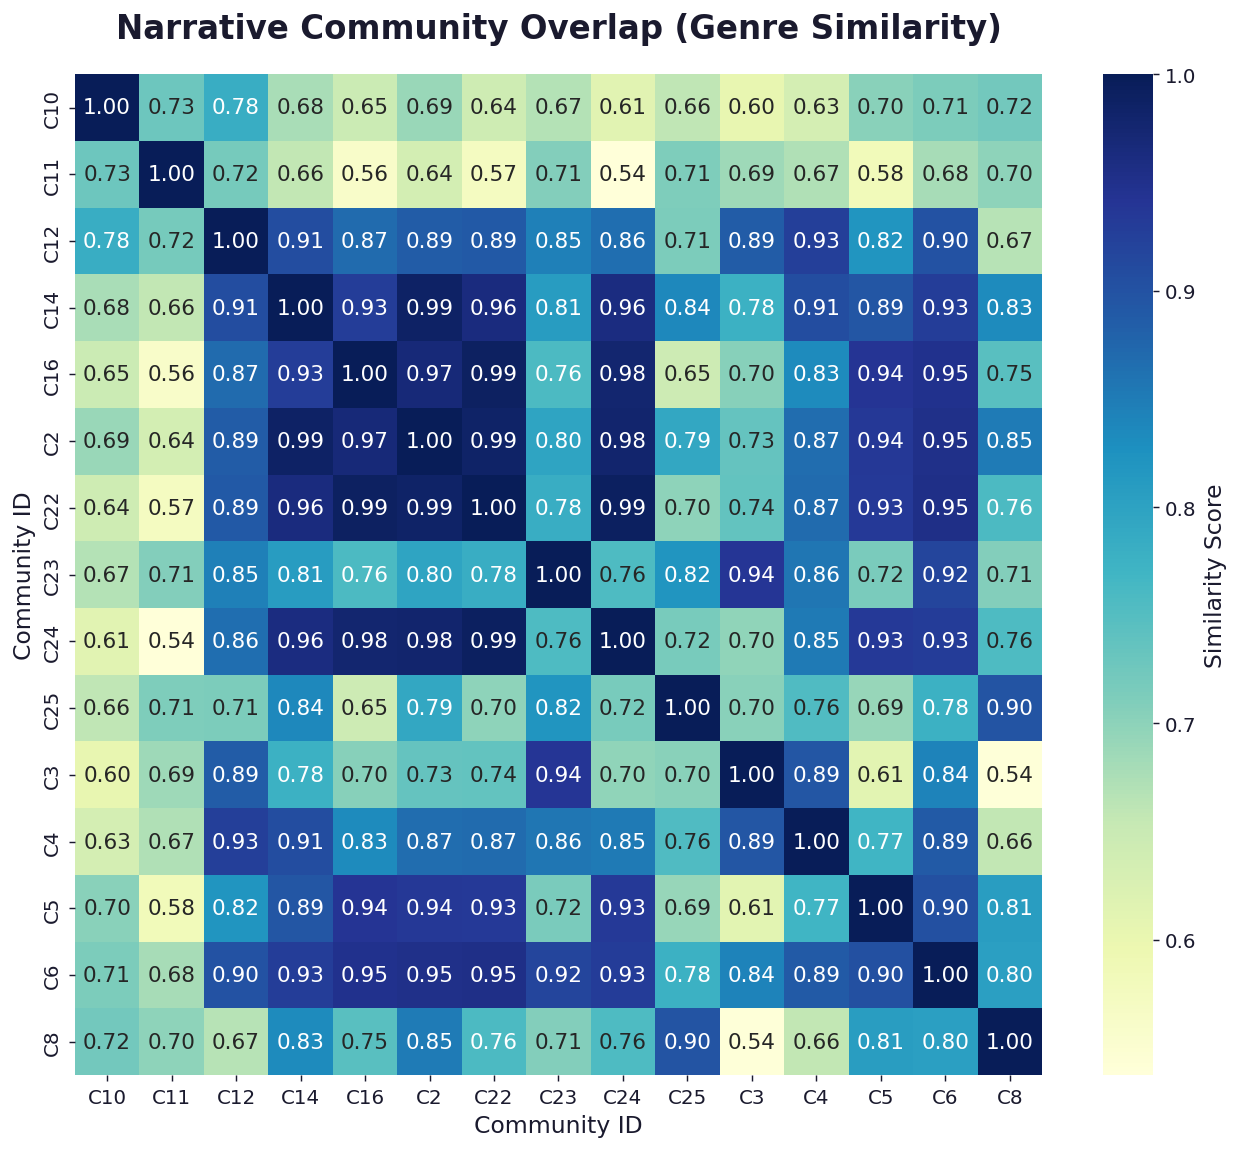

In [8]:
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

# 1. Extract genre distributions for major communities
genre_col = resolve_col(profile, ['top_primary_genres', 'top_genres'], '')

if genre_col:
    # Prepare a long-form dataframe of genres and their percentages per community
    genre_data = []
    major_comms = profile.sort_values('n_films', ascending=False).head(15) # Focus on top 15

    all_genres = set()
    for _, row in major_comms.iterrows():
        pairs = parse_genre_mix(row[genre_col], max_n=10)
        for g, v in pairs:
            all_genres.add(g)
            genre_data.append({'cid': f"C{int(row['community_id'])}", 'genre': g, 'value': v})

    # 2. Pivot to create a community-by-genre matrix
    df_genres = pd.DataFrame(genre_data).pivot(index='cid', columns='genre', values='value').fillna(0)

    # 3. Calculate Cosine Similarity between communities
    sim_matrix = cosine_similarity(df_genres)
    sim_df = pd.DataFrame(sim_matrix, index=df_genres.index, columns=df_genres.index)

    # 4. Plot Heatmap
    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(sim_df, annot=True, fmt='.2f', cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Similarity Score'})

    plt.title('Narrative Community Overlap (Genre Similarity)', pad=20, fontsize=18)
    plt.xlabel('Community ID')
    plt.ylabel('Community ID')

    save_fig(fig, '10_community_overlap_heatmap.png')
    plt.show()
else:
    print("Genre data not available to calculate overlap.")

## 12. Export Interpretation Note & Output Check

In [13]:
if nodes is not None:
    note = f"""
    Brick 4 — Narrative communities interpretation note
    ====================================================

    Main message
    ------------
    Community detection divides the plot-similarity network into narrative
    neighborhoods. These communities are NOT strict genres. They are groups of
    films whose plot descriptions place them near one another in the semantic network.

    Key numbers
    -----------
      Total detected communities      : {total_communities}
      Major interpreted communities   : {major_count}
      Minor communities               : {minor_count}
      Largest community size          : {int(profile['n_films'].max()):,} films
      Median community size           : {profile['n_films'].median():.0f} films
      Major-community threshold       : ≥ {CFG.major_threshold} films

    Recommended main thesis figures
    --------------------------------
      1. 01_community_detection_concept.png
      2. 02_major_communities_lollipop.png
      3. 04_top_communities_index_table.png
      4. Selected 05_community_profile_sheet_CXX.png
      5. 06_representative_films_gallery.png

    Recommended appendix / supporting figures
    ------------------------------------------
      1. 03_major_minor_community_split.png
      2. 07_community_size_vs_median_year.png
      3. 08_community_genre_mix_small_multiples.png
      4. 09_community_interpretation_summary.png

    Important wording
    -----------------
    The community labels are descriptive interpretations of plot-based clusters.
    They should NOT be described as objective genre labels or ground-truth categories.
    """.strip()

    write_text(note, "brick_04_interpretation_note.txt")
    print(note)

    print("\n" + "=" * 60)
    print("Output check")
    print("=" * 60)

    for label, directory in [("Figures", FIG_DIR), ("Tables", TABLE_DIR), ("Text", TEXT_DIR)]:
        files = sorted(directory.iterdir()) if directory.exists() else []
        print(f"\n{label} ({len(files)}):")
        for p in files:
            size_kb = p.stat().st_size / 1024
            print(f"  {size_kb:6.1f} kB  {p.name}")

    print("\nDone. ✓")

  Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/04_narrative_communities/text/brick_04_interpretation_note.txt
Brick 4 — Narrative communities interpretation note

    Main message
    ------------
    Community detection divides the plot-similarity network into narrative
    neighborhoods. These communities are NOT strict genres. They are groups of
    films whose plot descriptions place them near one another in the semantic network.

    Key numbers
    -----------
      Total detected communities      : 26
      Major interpreted communities   : 23
      Minor communities               : 3
      Largest community size          : 1,792 films
      Median community size           : 813 films
      Major-community threshold       : ≥ 100 films

    Recommended main thesis figures
    --------------------------------
      1. 01_community_detection_concept.png
      2. 02_major_communities_lollipop.png
      3. 04_top_communities_index_table.png
      4. Selec